# 4.0 – Recap: Initiation, Training and Evaluation

To recapitulate what we have learned about the AI Lifecycle from initiation to evaluation, we take face recognition as an end-to-end use case.

Face recognition systems are built on the assumption that each person has a similar face structure with indvidual characteristics. We all have a nose, a mouth, 2 ears, and cheeks, but they are composed slightly differently for everyone. This facilitates computerized face-matching. 

The work on face recognition has begun in the 1960's, the results of which are being used for security in various institutions and firms throughout the world. 

The images must be processed correctly for computer based face recognition. The face and its structural properties should be identified carefully, and the resulting image must be converted to two dimensional digital data.

![Img](./data/face_recognition.png)

For this task we use the dataset [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) which contains more than 13,000 images of faces collected from the web. Each face has been labeled with the name of the person pictured and contains 50*37 pixels with differents shades of white, grey, and black.



## Loading the Data (Labeled Faces in the Wild Dataset)
The lfw_people dataset is from scikit-learn and does not require downloading any file from some external website. The code below will load the dataset.

**Mac users might need to do some additional steps to read the data**: Go to Macintosh HD > Applications > Python3.6 folder (or whatever version of python you're using) > double click on "Install Certificates.command" file

In [ ]:
# load dataset
from sklearn.datasets import fetch_lfw_people

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
lfw_people.data

In [ ]:
# convert to pandas DataFrame
import pandas as pd

lfw_people_df = pd.DataFrame(data=lfw_people.data)
lfw_people_df['target'] = lfw_people.target
lfw_people_df.shape

If the download does not work, you can use the csv file from the data folder.

In [ ]:
import pandas as pd
from pathlib import Path


candidate_paths = [
  Path("data/lfw_people.csv"),
  Path("04_Exercise_4/data/lfw_people.csv"),
]


data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find data/lfw_people.csv. Start Jupyter in the repository root or 04_Exercise_4.")

print(f"Loading: {data_path.resolve()}")

df = pd.read_csv(data_path, index_col = 0)
df.shape

## Plotting Faces

In [4]:
# Define a function to plot faces
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline

def print_face(image):   
    plt.figure(figsize=(4,3))
    plt.imshow(np.reshape(image, (50,37)), cmap=plt.cm.gray)

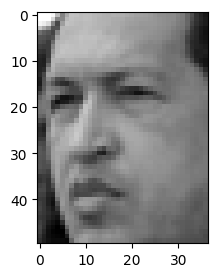

In [5]:
face_id = 0
print_face(lfw_people.data[face_id])

## Data Preprocessing

### **TASK: Data Preprocessing**

1. Explore and understand the dataset. Visualize relevant statistical properties of the dataset.
2. Transform the target column to a numeric feature.
3. Adapt the plotting function to plot an image from the dataset with the true target as plot title

In [ ]:
# Code up your solution here...

Now let us use the *Labeled Faces in the Wild Dataset* to actually learn and predict faces. Remember PCA from Exercise 1? Dimensionality reduction will be key here.

### **TASK: PCA**

1. Define features and the target variable
2. Compute a PCA on the entire dataset and construct 150 features. *Note: use `svd_solver='randomized'` and `whiten=True`*

In [ ]:
# Code up your solution here...

## What are Eigenfaces?

Eigenfaces is the name given to a set of eigenvectors when they are used in the computer vision problem of human face recognition. This approach for face recognition was developed in the late 1980's and is still used today.

You can imagine eigenfaces as a toolkit of generic faces that can be recombined to construct any face. Through PCA the set of generic faces within the toolkit can be minimized to represent the original training images with as little faces as possible. 

Let's look at some eigenfaces and test how well the eigenface representations can classify the true faces.

In [ ]:
# The principal components from the PCA combine the 1850 original features into the 150 eigenfaces
eigenfaces = pca.components_ # shape (n_components, n_features)
eigenfaces.shape

How does a generic face from the toolkit look like?

In [ ]:
print_face(eigenfaces[8])

Eerie, right? Now let us put these eerie faces to use.

### **TASK: Classification with Eigenfaces**

1. Split the PCA data into appropriate subsets.
2. Train a SVM classification model using a `GridSearchCV` with the following grid:
```python
param_grid = {'C': [1e3, 5e3, 1e4, 5e4, 1e5],
                 'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.1] }
```
3. Choose the best performing model and explain your choice.
4. Train an optimal final model version
5. Evaluate the final model's performance and compare it to a different parameter combination.
6. Visualize some predictions with your adapted plotting function. (*Hint: You can reconstruct the original dimensionality of the test set using ``pca.inverse_transform``*)

In [ ]:
# Code up your solution here...